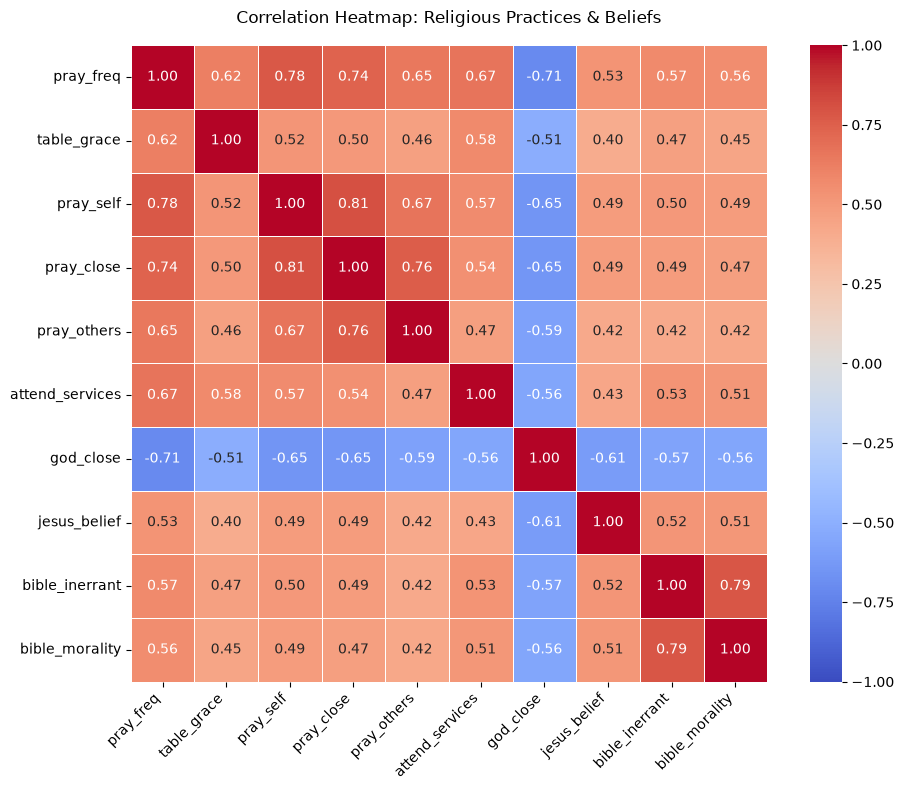

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_stata("chrisu.DTA", convert_categoricals=False)

# map variable codes to readable labels
var_mapping = {
    # Religious practices
    "V25": "pray_freq",  # About how often do you pray?
    "V26": "table_grace",  # Table prayers of grace before/after meals
    "V27": "pray_self",  # Pray about own personal needs
    "V28": "pray_close",  # Pray about needs of people close to you
    "V29": "pray_others",  # Pray about needs of others / current affairs
    "V34": "attend_services",  # How often do you attend religious services now?
    # Section B: Religious beliefs
    "V30": "god_close",  # How close do you feel to God most of the time?
    "V32": "jesus_belief",  # Personal beliefs about Jesus
    "V39": "bible_inerrant",  # Bible contains no errors / infallible Word of God
    "V41": "bible_morality",  # Bible is the final and complete guide to morality
}

# subset and rename columns
subset_df = df[list(var_mapping.keys())].rename(columns=var_mapping)

# Optional: Convert any special numeric missing codes (e.g., negative values) to NaN
# subset_df = subset_df.where(subset_df >= 0)

# correlation matrix --> spearman correlation
corr_matrix = subset_df.corr(method="pearson")

# correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
)

plt.title("Correlation Heatmap: Religious Practices & Beliefs", pad=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [3]:

import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from plotnine import *
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# could not find chris.dta fro some reason -- locate and load chrisu.dta automatically
skip_dirs = {".venv", "venv", "node_modules", ".git", ".Trash", "Applications", ".cache", "__pycache__"}
search_roots = [
    Path.cwd(),
    Path.home() / "Desktop",
    Path.home() / "Documents",
    Path.home() / "Downloads",
    Path.home() / "Library" / "Mobile Documents",
]

matches = []
for root in search_roots:
    if not root.exists():
        continue
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames[:] = [d for d in dirnames if d not in skip_dirs and not d.startswith(".")]
        for fname in filenames:
            if fname.lower() == "chrisu.dta":
                matches.append(Path(dirpath) / fname)

if not matches:
    raise FileNotFoundError(
        "Could not find chrisu.dta in the current directory, Desktop, Documents, Downloads, or iCloud Drive."
    )


data_path = next(
    (p for p in matches if "religion_logit" in str(p).lower()),
    matches[0],
)
print(f"Loaded file: {data_path}\n")

# convert_categoricals=False keeps underlying numeric codes from stata (.dta)
raw_df = pd.read_stata(data_path, convert_categoricals=False)

# prep variables
var_map = {
    # religious practices
    "V25": "pray_freq",
    "V26": "table_grace",
    "V27": "pray_self",
    "V28": "pray_close",
    "V29": "pray_others",
    "V34": "attend_services",
    # religious beliefs
    "V30": "god_close",
    "V39": "bible_inerrant",
    "V32": "V32",
    "V41": "V41",
}

df = raw_df[list(var_map.keys())].rename(columns=var_map).copy()
cols = list(var_map.values())

for c in cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

work = df.dropna(subset=cols).copy()
print(f"Complete cases retained: {len(work)} of {len(df)}\n")
print("=== Summary Statistics ===")
print(work[cols].describe().round(2))

# normalise varibles -- scale (mean 0, SD 1) and fit PCA
X = StandardScaler().fit_transform(work[cols])
pca = PCA().fit(X)

pc_names = [f"PC{i}" for i in range(1, len(cols) + 1)]
prop = pca.explained_variance_ratio_

variance_table = pd.DataFrame(
    {
        "Standard deviation": pca.explained_variance_ ** 0.5,
        "Proportion of variance": prop,
        "Cumulative proportion": prop.cumsum(),
    },
    index=pc_names,
).T.round(3)

Loaded file: /Users/elavainikrishnamoorthy/Desktop/hs4002_ay26/hs4002labs_2026/project/religion_logit/chrisu.DTA

Complete cases retained: 3009 of 3530

=== Summary Statistics ===
       pray_freq  table_grace  pray_self  pray_close  pray_others  \
count    3009.00      3009.00    3009.00     3009.00      3009.00   
mean        2.41         1.43       2.01        2.11         1.62   
std         1.67         1.22       1.38        1.40         1.29   
min         0.00         0.00       0.00        0.00         0.00   
25%         1.00         1.00       1.00        1.00         1.00   
50%         3.00         1.00       2.00        2.00         1.00   
75%         4.00         2.00       3.00        4.00         2.00   
max         5.00         4.00       4.00        4.00         4.00   

       attend_services  god_close  bible_inerrant      V32      V41  
count          3009.00    3009.00         3009.00  3009.00  3009.00  
mean              2.66       2.48            3.04     5.30

In [4]:
#loadings table
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

loadings = pd.DataFrame(
    pca.components_.T,
    index=cols,
    columns=pc_names,
)
print("=== Component Loadings ===")
print(loadings.round(3))

=== Component Loadings ===
                   PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8    PC9   PC10
pray_freq        0.362 -0.141  0.127  0.009 -0.248 -0.176  0.140  0.692  0.383  0.309
table_grace      0.281 -0.019  0.714  0.201  0.548 -0.188  0.128 -0.106 -0.078 -0.029
pray_self        0.341 -0.301 -0.107 -0.110 -0.224 -0.056  0.568 -0.090 -0.118 -0.609
pray_close       0.339 -0.363 -0.220 -0.127  0.072  0.108  0.193 -0.380 -0.204  0.670
pray_others      0.304 -0.400 -0.236 -0.200  0.450  0.228 -0.519  0.175  0.144 -0.278
attend_services  0.319  0.044  0.420  0.073 -0.511  0.572 -0.308 -0.138 -0.098 -0.043
god_close       -0.334 -0.018  0.153 -0.279  0.260  0.667  0.454  0.225  0.124  0.055
bible_inerrant   0.304  0.490 -0.049 -0.382  0.055 -0.030  0.059 -0.373  0.610 -0.021
V32              0.270  0.305 -0.383  0.720  0.192  0.306  0.173  0.069  0.062 -0.022
V41              0.297  0.512 -0.098 -0.381  0.108 -0.013 -0.008  0.336 -0.608  0.021


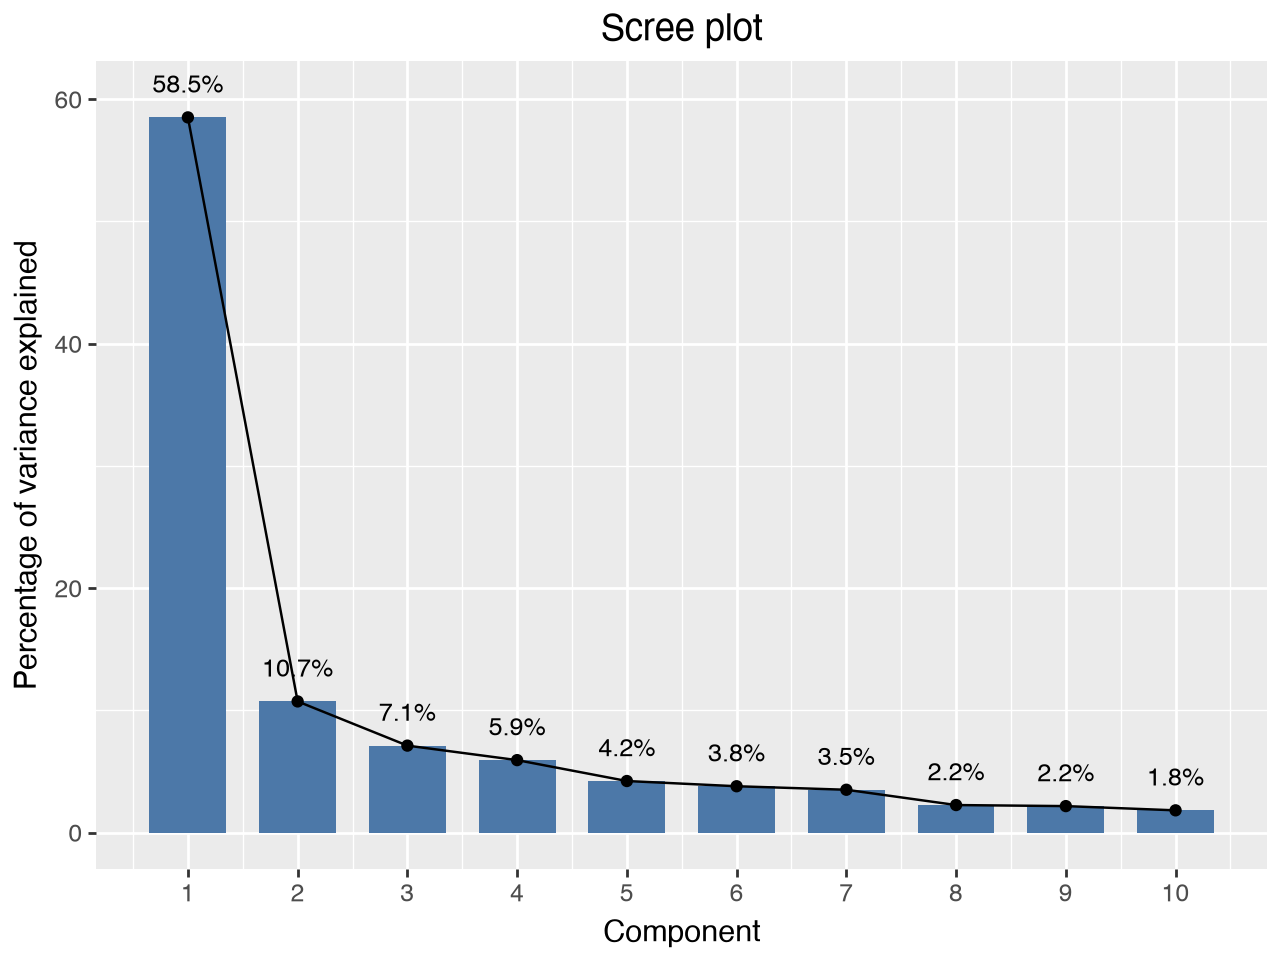

In [5]:
#scree plot
scree = pd.DataFrame(
    {
        "component": range(1, len(cols) + 1),
        "percent": pca.explained_variance_ratio_ * 100,
    }
)
scree["label"] = scree["percent"].map(lambda p: f"{p:.1f}%")

scree_plot = (
    ggplot(scree, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.6, size=9, va="bottom")
    + scale_x_continuous(breaks=range(1, len(cols) + 1))
    + labs(
        x="Component",
        y="Percentage of variance explained",
        title="Scree plot",
    )
)

scree_plot.save("scree_plot.png", dpi=300)
scree_plot

In [6]:
import statsmodels.formula.api as smf

work['PC1'] = pca.transform(X)[:, 0]

In [7]:
extra_map = {
    'V81': 'first_sex_code',            # age at first sexual intercourse (coded in bands)
    'V82': 'sex_partners_yr',           # sex partners in the past year
    'V83': 'sex_partners_lifetime',     # sex partners in lifetime
    'V86': 'unprotected_sex_stranger',  # unprotected sex with a stranger (0 = never ... 3 = almost always)
    'V3':  'gender_code',               # 1 = male, 2 = female
    'V2':  'race_code',                 # 1 = White, 2 = Black, 3 = Hispanic, 4 = Asian/Pacific Islander, 5 = Other
}
for old, new in extra_map.items():
    work[new] = pd.to_numeric(raw_df.loc[work.index, old], errors='coerce')

In [8]:
early_first_sex = work['first_sex_code'].between(1, 3)    # codes 1-3 = under 15, 15, 16 (assumed mapping)
deviant = (early_first_sex |
           (work['sex_partners_yr'] >= 1) |
           (work['sex_partners_lifetime'] >= 1) |
           (work['unprotected_sex_stranger'] >= 0))

In [9]:
sex_items = ['first_sex_code', 'sex_partners_yr', 'sex_partners_lifetime', 'unprotected_sex_stranger']
work['deviant'] = np.where(work[sex_items].isna().all(axis=1), np.nan, deviant.astype(float))
print(work['deviant'].value_counts(dropna=False))

deviant
1.0    2964
NaN      41
0.0       4
Name: count, dtype: int64


In [10]:
work['sex_woman'] = pd.Categorical(
    np.where(work['gender_code'] == 2, 'Woman', 'Not Woman'),
    categories=['Not Woman', 'Woman']
)
work['race_cat'] = pd.Categorical(
    work['race_code'].map({1: 'White', 2: 'Black', 3: 'Hispanic', 4: 'Asian_PI', 5: 'Other'}),
    categories=['White', 'Black', 'Hispanic', 'Asian_PI', 'Other']
)

# Keep respondents with complete data on everything in the model
model_df = work.dropna(subset=['deviant', 'PC1', 'gender_code', 'race_code']).copy()
print('N in model:', len(model_df))

N in model: 2928


In [11]:
logit_dev = smf.logit('deviant ~ PC1 + sex_woman + race_cat', data=model_df).fit(maxiter=100)
print(logit_dev.summary())

Optimization terminated successfully.
         Current function value: 0.007806
         Iterations 37


LinAlgError: Singular matrix

In [17]:
# rebuild outcome with new stricter thresholds; the old thresholds fail because only 4 of 2,928
# people are coded 0, spread across a few race categories, so the model can't be estimated
deviant = (work['first_sex_code'].between(1, 3) |       # first sex under 15, 15 or 16 (assumed mapping)
           (work['sex_partners_yr'] >= 3) |
           (work['sex_partners_lifetime'] >= 5) |
           (work['unprotected_sex_stranger'] >= 1))
work['deviant'] = np.where(work[sex_items].isna().all(axis=1), np.nan, deviant.astype(float))

# rebuild model_df from work
model_df = work.dropna(subset=['deviant', 'PC1', 'gender_code', 'race_code']).copy()
print('Share coded deviant:', round(model_df['deviant'].mean(), 3))   # should print about 0.364

logit_dev = smf.logit('deviant ~ sex_woman + race_cat + PC1', data=model_df).fit()
print(logit_dev.summary())

Share coded deviant: 0.364
Optimization terminated successfully.
         Current function value: 0.630718
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                deviant   No. Observations:                 2928
Model:                          Logit   Df Residuals:                     2921
Method:                           MLE   Df Model:                            6
Date:                Sun, 15 Nov 2026   Pseudo R-squ.:                 0.03786
Time:                        10:58:26   Log-Likelihood:                -1846.7
converged:                       True   LL-Null:                       -1919.4
Covariance Type:            nonrobust   LLR p-value:                 7.536e-29
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -0.3822      0.069     -5.503      0.

In [ ]:
logit_dev = smf.logit('deviant ~ sex_woman + race_cat + PC1', data=model_df).fit()
print(logit_dev.summary())

from stargazer.stargazer import Stargazer

# reograninsing so the controls appear first before pc1's row of estimates
sg = Stargazer([logit_dev])
sg.title('Sexual Deviance')
sg.custom_columns(['Logit'], [1])
sg.covariate_order(['sex_woman[T.Woman]', 'race_cat[T.Black]', 'race_cat[T.Hispanic]',
                    'race_cat[T.Asian_PI]', 'race_cat[T.Other]', 'PC1', 'Intercept'])
sg.rename_covariates({
    'sex_woman[T.Woman]': 'Woman',
    'race_cat[T.Black]': 'Black',
    'race_cat[T.Hispanic]': 'Hispanic',
    'race_cat[T.Asian_PI]': 'Asian/Pacific Islander',
    'race_cat[T.Other]': 'Other race',
})

# Ending the cell on the object itself renders the table in the notebook
sg

Optimization terminated successfully.
         Current function value: 0.630718
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                deviant   No. Observations:                 2928
Model:                          Logit   Df Residuals:                     2921
Method:                           MLE   Df Model:                            6
Date:                Sun, 15 Nov 2026   Pseudo R-squ.:                 0.03786
Time:                        10:49:36   Log-Likelihood:                -1846.7
converged:                       True   LL-Null:                       -1919.4
Covariance Type:            nonrobust   LLR p-value:                 7.536e-29
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -0.3822      0.069     -5.503      0.000      -0.518      -0.246

on average, an one unit increase in an indivudal displaying behaviours representative of PC1 is expected to cause a 0.163 decrease in log odds of engaging in sexually devinat behaviour.  

In [18]:
!pip install marginaleffects
from marginaleffects import avg_comparisons, comparisons
avg_comparisons(logit_dev, variables=['PC1', 'sex_woman', 'race_cat'])
comparisons(logit_dev, variables='PC1', newdata='mean')



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


term,contrast,estimate,std_error,statistic,p_value,s_value,conf_low,conf_high
str,str,f64,f64,f64,f64,f64,f64,f64
"""PC1""","""+1""",-0.036682,0.003804,-9.644214,0.0,inf,-0.04414,-0.029224


on average, a one-unit increase in PC1 (individual subscribing to orthodox Christian rpinciples and practices) is associated with a 3.7 percentage decrease in the probability of engaging in sexually deviant behaviours, ceteris paribus (p < .001).

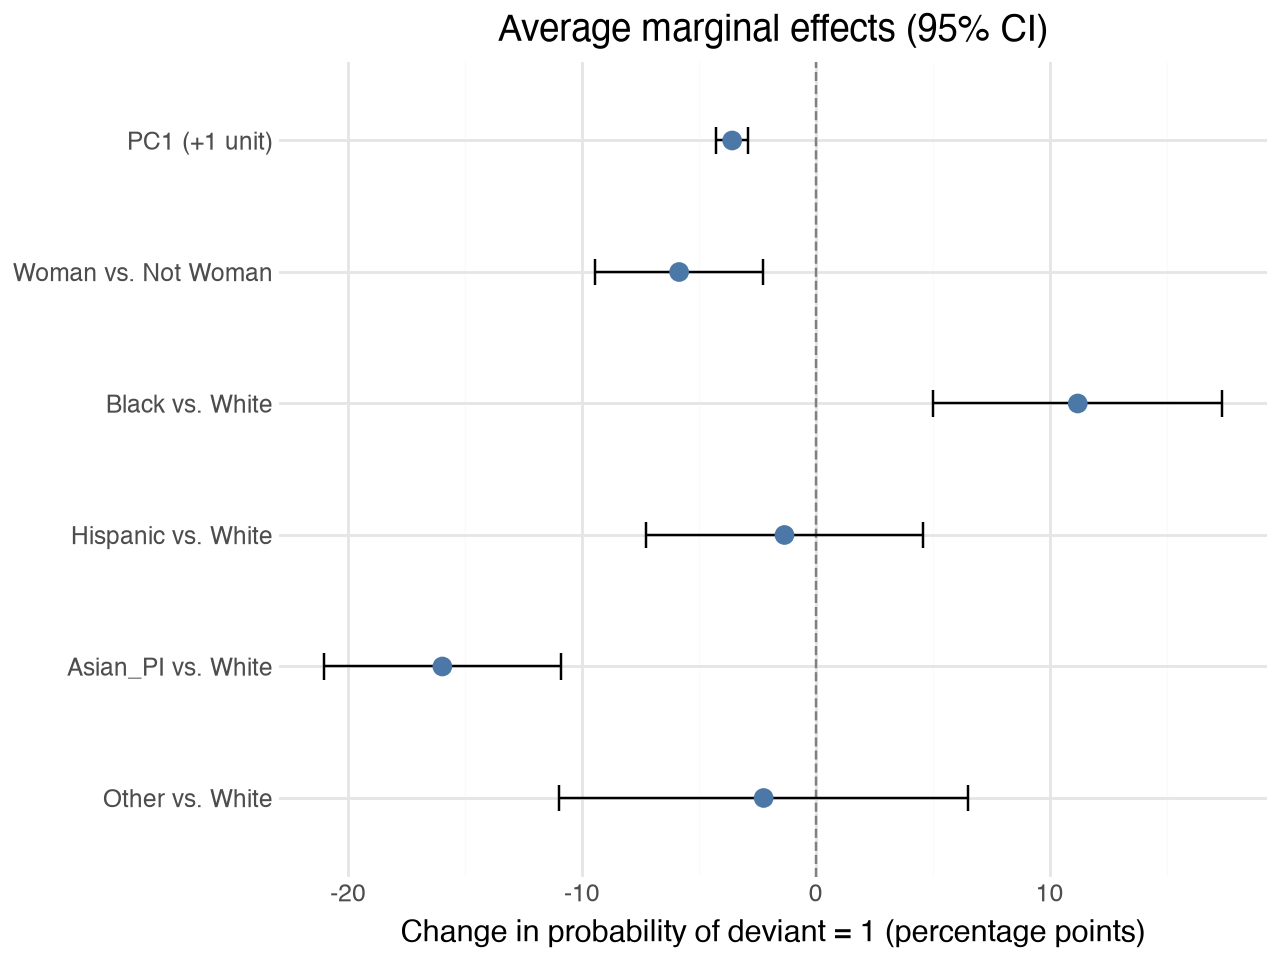

In [19]:
from plotnine import *
from marginaleffects import avg_comparisons

# Compute the average marginal effects and convert to a pandas dataframe
ame = avg_comparisons(logit_dev, variables=['PC1', 'sex_woman', 'race_cat'])
ame_df = ame.to_pandas()

# Readable labels
ame_df['label'] = ame_df['contrast'].where(ame_df['term'] != 'PC1', 'PC1 (+1 unit)')
ame_df['label'] = ame_df['label'].replace({'Woman - Not Woman': 'Woman vs. Not Woman'})
ame_df['label'] = ame_df['label'].str.replace(' - ', ' vs. ', regex=False)

# Convert probabilities to percentage points
ame_df['pp'] = ame_df['estimate'] * 100
ame_df['lo'] = ame_df['conf_low'] * 100
ame_df['hi'] = ame_df['conf_high'] * 100

# Reverse the order so the first term appears at the top of the plot
ame_df['label'] = pd.Categorical(ame_df['label'], categories=ame_df['label'].tolist()[::-1])

(
    ggplot(ame_df, aes(x='pp', y='label'))
    + geom_vline(xintercept=0, linetype='dashed', color='grey')   # no-effect line
    + geom_errorbarh(aes(xmin='lo', xmax='hi'), height=0.2)
    + geom_point(size=3, color='#4C78A8')
    + labs(x='Change in probability of deviant = 1 (percentage points)', y='',
           title='Average marginal effects (95% CI)')
    + theme_minimal()
)